# TP1 : Initiation au traitement d’images avec OpenCV

In [32]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

### 1.1. Importer une image

In [2]:
image = cv2.imread('Cat.jpg')
# informations
print( 'classe :', type(image) )
print( 'type :', image.dtype )
print( 'taille :', image.shape )
print(image[0,0]) # accède à la valeur du premier pixel

classe : <class 'numpy.ndarray'>
type : uint8
taille : (225, 300, 3)
[243 243 243]


### 1.2. Afficher l'image

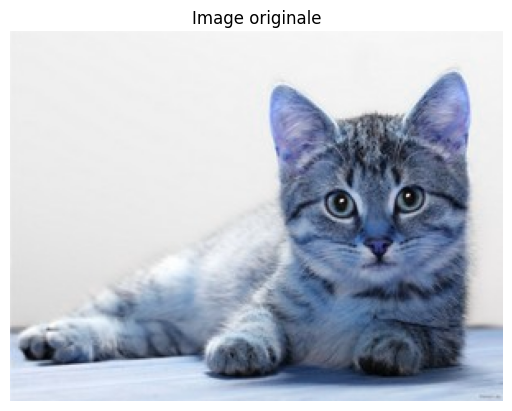

In [3]:
plt.imshow(image)
plt.title("Image originale")
plt.axis('off')
plt.show()

**Pourquoi les couleurs de cette image sont complétement différentes de l’image originale?**

OpenCV utilise l'ordre BGR (Bleu, Vert, Rouge) pour les canaux de couleur lorsqu'il charge une image
avec cv2.imread(). En revanche, matplotlib (et de nombreuses autres bibliothèques) utilisent
l'ordre RGB (Rouge, Vert, Bleu) pour afficher les images. Cela signifie que l'image affichée avec
matplotlib apparaîtra dans des couleurs inversées si vous l'affichez directement après l'avoir lue avec
OpenCV.

OpenCV loads images as **BGR**

Matplotlib expects **RGB**

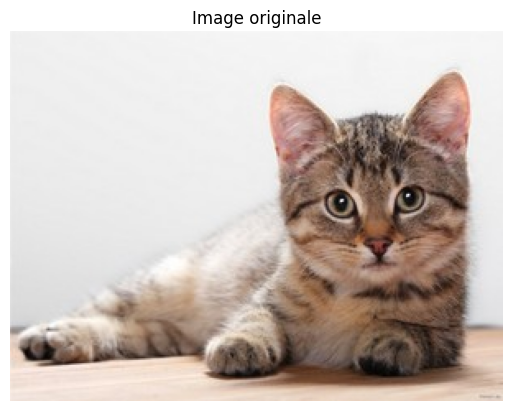

In [5]:
#How to convert BGR to RGB: solution1
b, g, r = cv2.split(image)
image2 = cv2.merge([r, g, b])
plt.imshow(image2)
plt.title("Image originale")
plt.axis('off')
plt.show()

La fonction split() de OpenCV prend une image couleur et sépare ses canaux.

👉 Une image couleur = 3 matrices : B (Blue), G (Green), R (Red)

Résultat :

b = image en niveaux de gris du canal bleu

g = canal vert

r = canal rouge

Chaque variable est une matrice 2D (une seule couche).

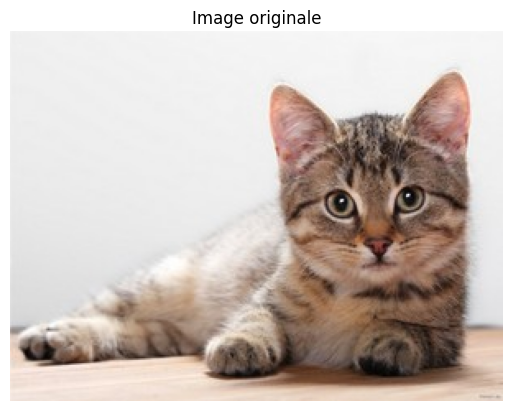

In [6]:
#How to convert BGR to RGB: solution2 more frequently used
img_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.title("Image originale")
plt.axis('off')
plt.show()

### 1.3. Sauvegarder l'image

In [7]:
cv2.imwrite('Cat_bis.jpg', image)

True

'Cat_bis.jpg' → nom du fichier

image → matrice (ton image en mémoire), les données de l’image à enregistrer

➡️ OpenCV prend cette matrice et la transforme en fichier .jpg

### 1.4. Image en niveaux de gris


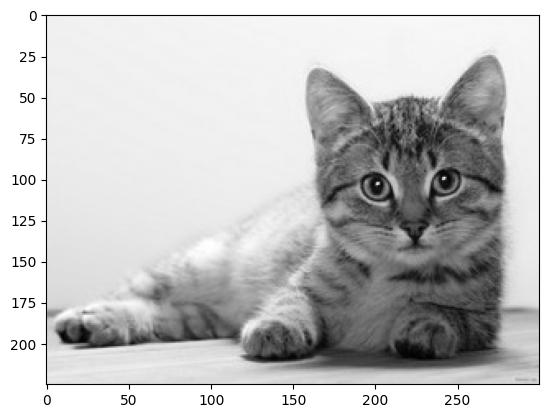

taille de l'image en nuance de gris : (225, 300)


In [22]:
grey_image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
plt.imshow(grey_image, cmap = 'gray') #gray: colormap de nuances de gris
plt.show()
print("taille de l'image en nuance de gris :", grey_image.shape)

In [23]:
cv2.imwrite('Cat_grey.jpg', grey_image)

True

Désormais, vous avez un seul canal (plus de RGB). Votre matrice est de taille NxM, et non NxMx3

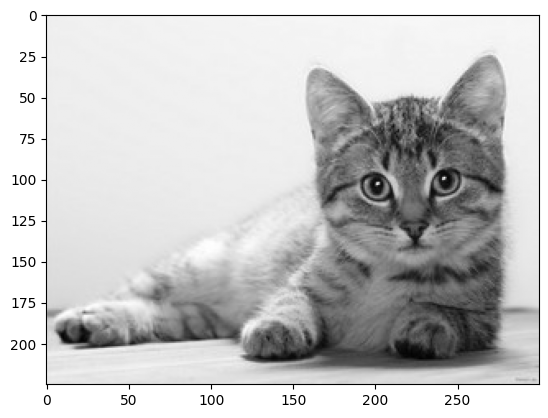

taille de l'image en nuance de gris : (225, 300)


In [20]:
grey_image2 = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(grey_image2, cmap = 'gray') #gray: colormap de nuances de gris
plt.show()
cv2.imwrite('Cat_grey2.jpg', grey_image2)
print("taille de l'image en nuance de gris :", grey_image2.shape)

### 1.5. Changer la taille d’une image (sous-échantillonnage)

In [33]:
fleur = cv2.imread('fleur.png')

In [34]:
print( 'dimensions de l’image :', fleur.shape )

dimensions de l’image : (324, 324, 3)


In [35]:
fleur = cv2.cvtColor(fleur, cv2.COLOR_BGR2RGB)

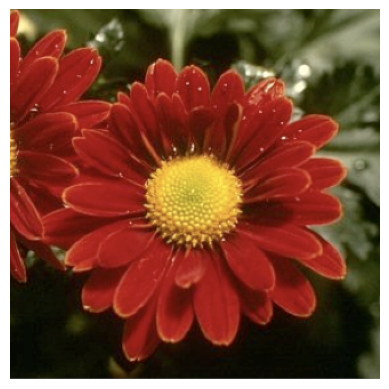

In [36]:
plt.imshow(fleur)
plt.axis('off')
plt.show()

In [43]:
height, width = fleur.shape[:2]
new_width = width // 2
new_height = height // 2
resized_image = cv2.resize(fleur, (new_width, new_height))

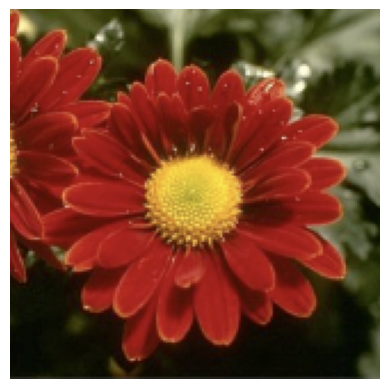

(162, 162, 3)

In [44]:
plt.imshow(resized_image)
plt.axis('off')
plt.show()
resized_image.shape

### 1.6. Crop d’une image

Le crop (ou recadrage) d'une image consiste à découper une portion de l'image en spécifiant les
coordonnées du rectangle à extraire. Le découpage est effectué avec la syntaxe **image[x1:x2, y1:y2]**, où x1:x2 représente les lignes et y1:y2 les colonnes.

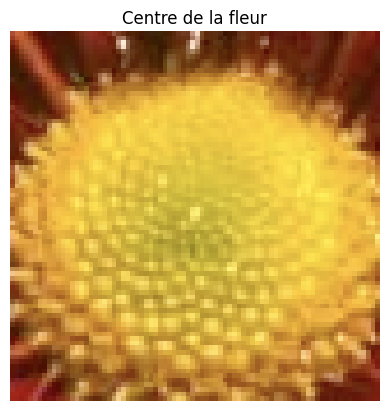

In [59]:
cropped_image = fleur[120:200, 120:200]
plt.imshow(cropped_image)
plt.title("Centre de la fleur")
plt.axis('off')
plt.show()

### 1.7. Appliquer des rotations et des translations
**Rotation**

La rotation d’une image consiste à faire pivoter l’image autour d’un point de référence, généralement son
centre, selon un certain angle.

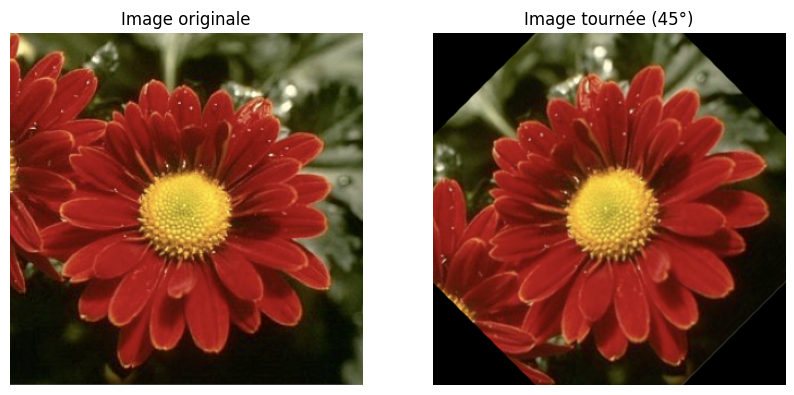

In [62]:
center = (width // 2, height // 2)
angle = 45  # rotation de 45 degrés
scale = 1   # pas de zoom
rotation_matrix = cv2.getRotationMatrix2D(center, angle, scale)
# Appliquer la rotation
rotated_image = cv2.warpAffine(fleur, rotation_matrix, (width, height))
# Affichage
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(fleur)
plt.title("Image originale")
plt.axis('off')
plt.subplot(1,2,2)
plt.imshow(rotated_image)
plt.title("Image tournée (45°)")
plt.axis('off')
plt.show()

**Translation**

La translation consiste à déplacer l'image sur les axes X et Y. Dans OpenCV.

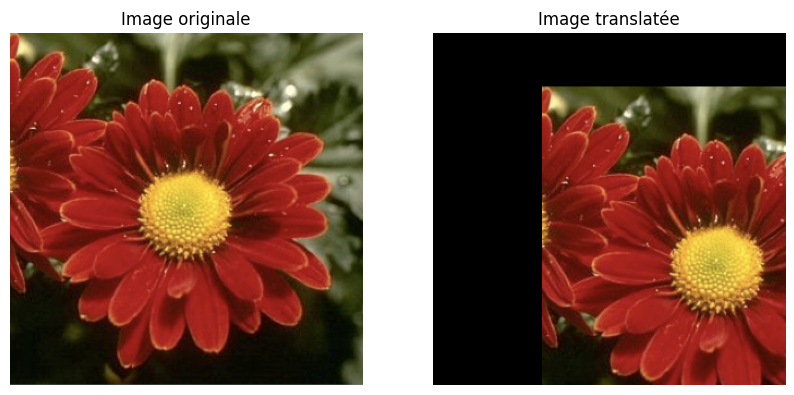

In [63]:
# Définir translation
tx = 100   # déplacement vers la droite
ty = 50    # déplacement vers le bas

# Matrice de translation
translation_matrix = np.float32([
    [1, 0, tx],
    [0, 1, ty]
])

# Appliquer la translation
translated_image = cv2.warpAffine(fleur, translation_matrix, (width, height))

# Affichage
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(fleur)
plt.title("Image originale")
plt.axis('off')
plt.subplot(1,2,2)
plt.imshow(translated_image)
plt.title("Image translatée")
plt.axis('off')
plt.show()

### **Exercice 1:**

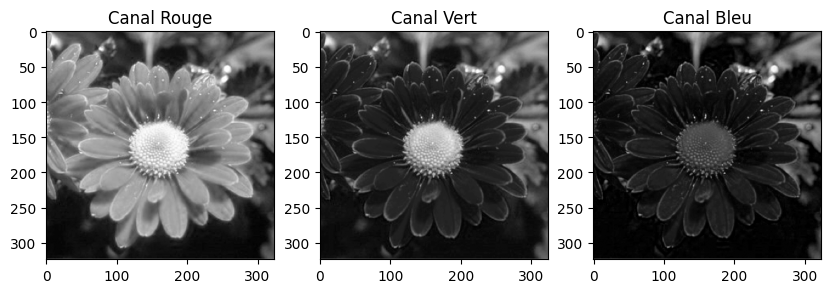

In [64]:
fleur = cv2.imread("fleur.png")
fleur_rgb = cv2.cvtColor(fleur, cv2.COLOR_BGR2RGB)
b, g, r = cv2.split(fleur)
plt.figure(figsize=(10,4))
plt.subplot(1,3,1)
plt.imshow(r, cmap='gray')
plt.title("Canal Rouge")
plt.subplot(1,3,2)
plt.imshow(g, cmap='gray')
plt.title("Canal Vert")
plt.subplot(1,3,3)
plt.imshow(b, cmap='gray')
plt.title("Canal Bleu")
plt.show()

* Plus c’est clair → plus la couleur est présente.

**Images binaires (dominance des couleurs)**

In [66]:
# Rouge dominant
red_dom = (r > g) & (r > b)
# Vert dominant
green_dom = (g > r) & (g > b)
# Bleu dominant
blue_dom = (b > r) & (b > g)

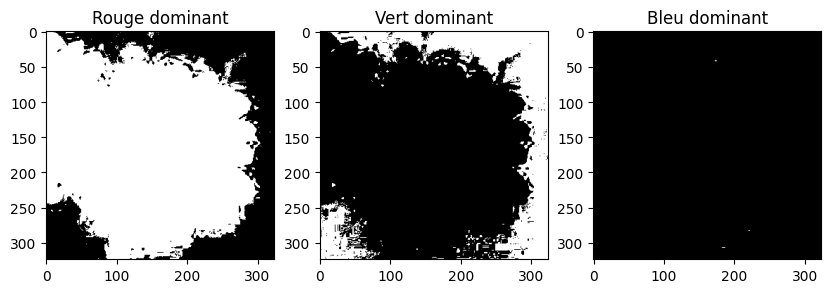

In [67]:
plt.figure(figsize=(10,4))
plt.subplot(1,3,1)
plt.imshow(red_dom, cmap='gray')
plt.title("Rouge dominant")
plt.subplot(1,3,2)
plt.imshow(green_dom, cmap='gray')
plt.title("Vert dominant")
plt.subplot(1,3,3)
plt.imshow(blue_dom, cmap='gray')
plt.title("Bleu dominant")
plt.show()

Chaque image (red_dom, green_dom, blue_dom) est :

* une image noir et blanc

* blanc = couleur dominante

* noir = sinon

(np.float64(-0.5), np.float64(458.5), np.float64(458.5), np.float64(-0.5))

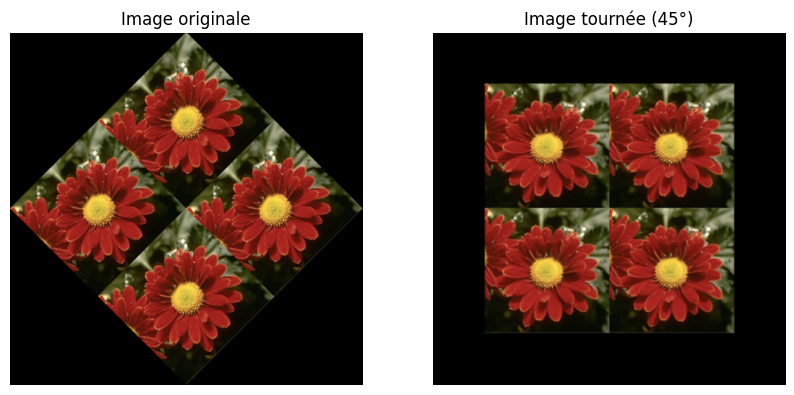

In [74]:
fleurModif = cv2.imread("fleurModif.png")
width, height = fleurModif.shape[:2]
center = (width // 2, height // 2)
angle = -45  # rotation de 45 degrés
scale = 1   # pas de zoom
rotation_matrix = cv2.getRotationMatrix2D(center, angle, scale)
# Appliquer la rotation
rotated_image = cv2.warpAffine(fleurModif, rotation_matrix, (width, height))
fleurModif = cv2.cvtColor(fleurModif, cv2.COLOR_BGR2RGB)
rotated_image = cv2.cvtColor(rotated_image, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(fleurModif)
plt.title("Image originale")
plt.axis('off')
plt.subplot(1,2,2)
plt.imshow(rotated_image)
plt.title("Image tournée (45°)")
plt.axis('off')

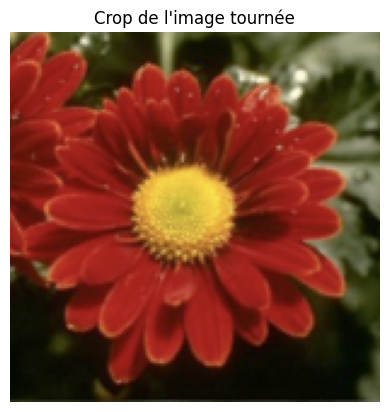

True

In [87]:
cropped_image = rotated_image[width//6:width//2, height//6:height//2]
plt.imshow(cropped_image)
plt.title("Crop de l'image tournée")
plt.axis('off')
plt.show()
cv2.imwrite('resultat.jpg', cv2.cvtColor(cropped_image, cv2.COLOR_RGB2BGR))

### **Exercice 2:**


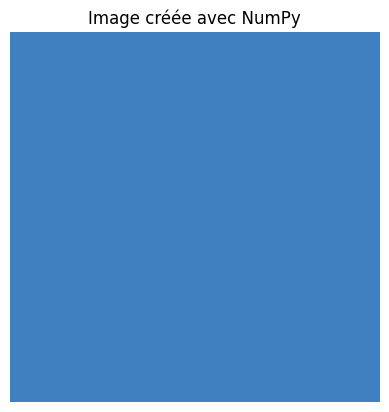

In [88]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Créer une image 5x5 avec 3 canaux (RGB)
img = np.zeros((5, 5, 3), dtype=np.uint8)

# 2. Remplir les canaux avec des valeurs
img[:, :, 0] = 64   # Rouge
img[:, :, 1] = 128  # Vert
img[:, :, 2] = 192  # Bleu

# 3. Convertir le tableau NumPy en image PIL
img_pil = Image.fromarray(img)

# 4. Afficher l'image
plt.imshow(img_pil)
plt.title("Image créée avec NumPy")
plt.axis('off')
plt.show()

# 5. Sauvegarder l'image
img_pil.save("Image_from_array.png")